# Qu’est-ce que le machine learning ?

>Le **machine learning**, ou **apprentissage automatique**, consiste à apprendre une règle à partir d’exemples. 

>On appelle cette règle un **modèle**. 

>À l’imprimerie, les exemples viennent des commandes terminées. La règle servira au comptoir, quand la prochaine cliente demandera combien de temps elle doit attendre.

## Comprendre · À quoi ça sert ?

> « Si je commande cinq carnets, combien de temps faudra-t-il ? »
>
> *Une cliente, au comptoir de l’imprimerie*

Pour lui répondre, l’imprimeur connaît la durée de commandes déjà terminées. Il voudrait s’en servir pour **estimer une durée avant de commencer**. C’est un usage du machine learning.

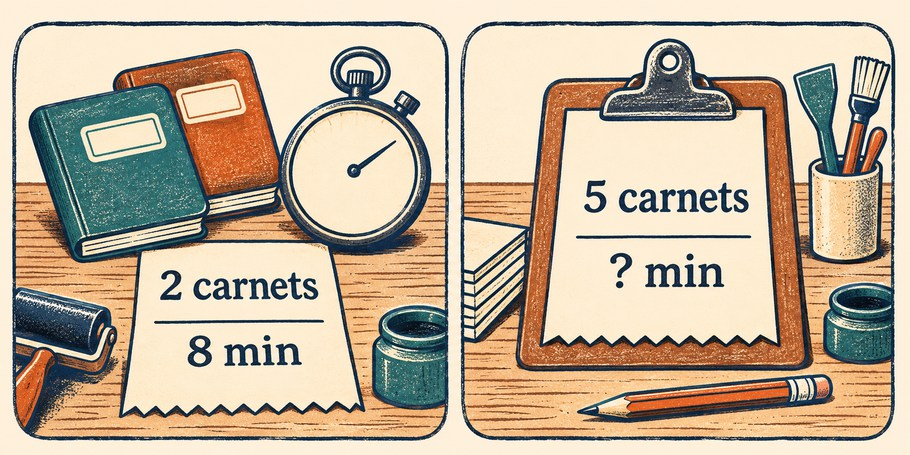

> **Lis les tickets.** Quelle information l’imprimeur connaît-il dès la commande ? Laquelle doit-il encore estimer à droite ?

Sur le ticket de gauche, deux carnets ont demandé huit minutes. Sur celui de droite, l’imprimeur connaît déjà la quantité, **cinq carnets**. La case encore vide est celle de la **durée**.

Les huit minutes du premier ticket lui donnent un exemple pour répondre à la cliente. Imagine maintenant que les anciens tickets indiquent les quantités, mais que personne n’ait jamais noté les durées. Que pourrait-il encore apprendre de ces tickets ?

## Qu’est-ce que les anciens tickets permettent d’apprendre ?

**Quand la durée est notée**, l’imprimeur peut s’exercer. Il cache les « huit minutes » du ticket de deux carnets, propose une durée, puis retourne le ticket pour vérifier sa réponse. Sur chaque commande terminée, la bonne réponse est là pour guider l’apprentissage. C’est ce que signifie **apprentissage supervisé**.

**Quand la durée manque partout**, il ne peut plus vérifier combien de minutes il fallait. Il peut en revanche chercher des ressemblances. Si ses tickets indiquent la quantité et le type de papier, il peut par exemple rapprocher les petites commandes sur papier épais. Aucun groupe ne lui a été donné à deviner. Chercher une organisation de cette façon s’appelle un **apprentissage non supervisé**. Tu essaieras ce regroupement toi-même avec des données de fréquentation.

Reviens à la cliente qui attend un délai. L’imprimeur a bien conservé les durées de quatre essais. S’il transforme ces quatre tickets en tableau, quelle colonne pourra-t-il remplir **avant** de fabriquer les carnets ? Laquelle devra-t-il remplir **après** ?

## Deux colonnes pour apprendre

Voici les quatre tickets recopiés. Chaque ligne correspond à une commande faite avec le même papier.

| Carnets commandés | Durée mesurée après fabrication |
|---:|---:|
| 1 | 6 minutes |
| 2 | 8 minutes |
| 3 | 10 minutes |
| 4 | 12 minutes |

Lis la deuxième ligne comme si tu étais au comptoir. **Avant** la fabrication, tu peux écrire « 2 carnets ». Cette information fournie à la règle est une **entrée**. Dans les exemples Python, le tableau des entrées s’appellera `X`.

**Après** la fabrication, tu peux ajouter « 8 minutes ». C’est la réponse que tu voudras apprendre à estimer sur d’autres commandes. On l’appelle la **cible** et on la note souvent `y`. Quand la cliente demandera cinq carnets, tu auras son `X`, mais tu attendras encore son `y`.

> Cache la durée de la quatrième ligne. D’après les trois premières, combien de minutes proposerais-tu pour quatre carnets ?

En ajoutant deux minutes par carnet, tu proposes **12 minutes**. Découvre la ligne pour vérifier. Comment reprendre ce petit jeu avec des commandes qui n’ont pas servi à trouver la règle ?

## Garder des commandes de côté pour vérifier la règle

L’imprimeur peut glisser quelques tickets terminés dans une enveloppe avant de chercher sa règle. Plus tard, il fera comme si ces clients venaient juste de commander.

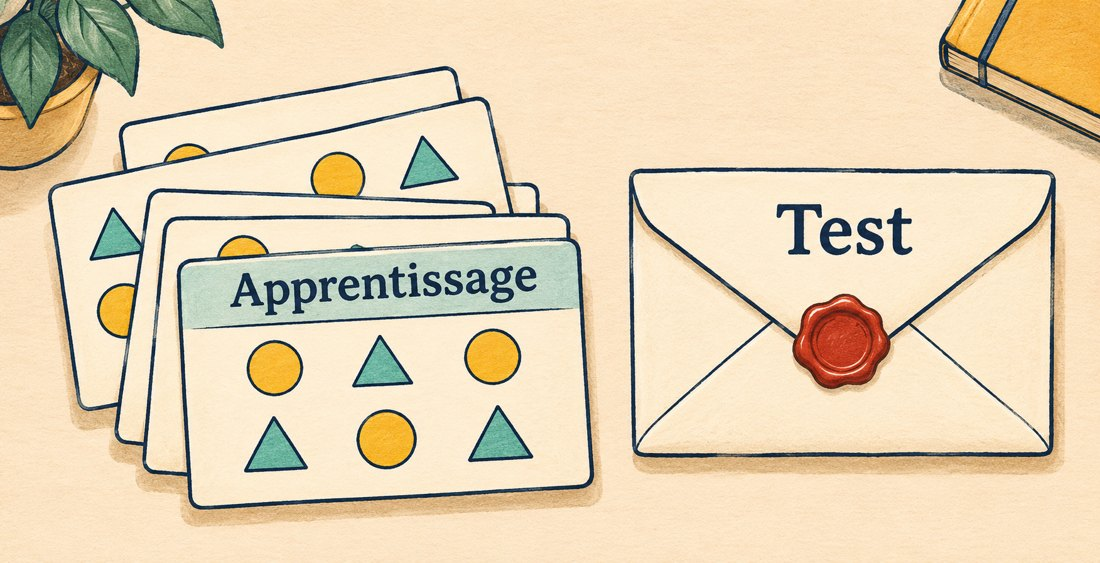

1. Les tickets restés sur la table montrent les quantités **et** les durées. Ils servent à trouver la règle. Ce sont les **données d’apprentissage**.
2. Pour les tickets de l’enveloppe, il lit seulement les quantités et note les durées que propose sa règle. Chacune de ces estimations s’appelle une **prédiction**.
3. Il dévoile enfin les durées mesurées et les compare à ses annonces. Les tickets réservés pour cette vérification forment les **données de test**.

S’il change sa règle pour mieux réussir sur ces tickets, il lui faudra une nouvelle enveloppe pour la vérifier. Nous ferons l’expérience sur un registre de 24 commandes. D’abord, sur les quatre essais du tableau, quel calcul l’imprimeur pourrait-il déjà faire à la main pour répondre à sa cliente ?

## Trouver une première règle à la main

Dans les quatre essais, un carnet supplémentaire ajoute deux minutes. La première commande prend six minutes, donc il reste quatre minutes fixes une fois retranchées les deux minutes du carnet. Avec cinq carnets, le calcul est **4 + 2 × 5**. Quel nombre devrais-tu voir ?

Fais d’abord le calcul de tête. Clique ensuite sur le bloc de code, appelé une *cellule* dans Jupyter. Appuie sur **Maj + Entrée** pour l’exécuter et vérifier ta réponse.

In [5]:
carnets = 5
minutes = 4 + 2 * carnets
print(minutes)

14


1. `carnets = 5` garde la quantité commandée sous le nom `carnets`.
2. `4 + 2 * carnets` compte les 4 minutes de préparation et les 2 minutes par carnet. En Python, `*` signifie « multiplier ».
3. `print(minutes)` affiche la durée obtenue.

> **À toi.** Remplace 5 par 8 et relance la cellule. Si tu obtiens **20 minutes**, tu as appliqué la même règle à une nouvelle commande.

Avec cette règle, tu viens d’estimer une quantité mesurable, un nombre de minutes. En machine learning, cette tâche porte un nom, la **régression**. Pour l’instant, c’est toi qui as trouvé les deux nombres de la règle. Comment les faire retrouver à Python à partir des quatre commandes terminées ?

## Faire apprendre la règle à Python avec scikit-learn

On peut donner à Python les quatre quantités avec leurs durées et lui demander de retrouver la règle. **Scikit-learn** fournit l’outil pour faire ce calcul. C’est une **bibliothèque**, autrement dit un ensemble d’outils déjà écrits qu’on peut appeler dans un programme Python.

Imagine un dessin avec le nombre de carnets à l’horizontale et la durée à la verticale. Chaque ticket donne un point. On demande à Python de tracer une **droite** qui passe aussi près que possible des durées observées. Estimer un nombre avec une droite s’appelle une **régression linéaire**. La droite du premier exemple sera dessinée juste après le calcul.

Lis les deux imports comme des demandes d’outils.

- `import pandas as pd` donne le nom court `pd` à pandas. On s’en sert pour ranger les tickets dans un tableau appelé `DataFrame`.
- `from sklearn.linear_model import LinearRegression` prend l’outil qui ajuste la droite. La bibliothèque s’installe sous le nom **scikit-learn** et s’écrit **`sklearn`** dans un import.

Dans la cellule, `LinearRegression()` crée un modèle qui n’a encore vu aucun ticket. L’appel `fit(X_essais, y_essais)` lui montre les quantités et les durées correspondantes. **`fit` signifie ici « ajuster la règle aux exemples »**. Exécute la cellule et regarde si Python retrouve tes deux nombres.

In [18]:
import pandas as pd
from sklearn.linear_model import LinearRegression

essais = pd.DataFrame({"carnets": [1, 2, 3, 4], "minutes": [6, 8, 10, 16]})
X_essais = essais[["carnets"]]
y_essais = essais["minutes"]

modele_duree = LinearRegression()
modele_duree.fit(X_essais, y_essais)
print(f"Minutes fixes estimées : {modele_duree.intercept_:.1f}")
print(f"Minutes par carnet : {modele_duree.coef_[0]:.1f}")

Minutes fixes estimées : 2.0
Minutes par carnet : 3.2


| Dans le code | Comment lire cette ligne |
|---|---|
| `pd.DataFrame(…)` | Pandas construit le tableau des quatre commandes. `pd` est le nom court donné à pandas dans l’import. |
| `essais[["carnets"]]` | Les doubles crochets gardent un tableau à une colonne, la forme attendue pour X. |
| `essais["minutes"]` | Une seule paire de crochets extrait la série des réponses y. |
| `LinearRegression()` puis `.fit(…)` | Crée puis entraîne un modèle de régression linéaire. |
| `intercept_` et `coef_[0]` | Lisent les deux nombres appris, 4 minutes fixes et 2 minutes par carnet supplémentaire. Le premier coefficient porte le numéro 0 en Python. |

Python a retrouvé **4 minutes fixes** et **2 minutes par carnet**. Que va-t-il annoncer si on lui donne maintenant seulement les quantités 5 et 8 ? Dans la cellule suivante, **`predict` signifie « appliquer la règle apprise pour obtenir une estimation »**. Les deux résultats apparaîtront dans le même ordre que les commandes.

In [7]:
a_preparer = pd.DataFrame({"carnets": [5, 8, 30]})
print(modele_duree.predict(a_preparer))

[14. 20. 64.]


## Visualiser · Lire une durée sur la droite

La sortie donne **14 minutes pour cinq carnets** et **20 minutes pour huit**. Pour retrouver les 14 minutes sur le dessin, pars de 5 sur l’axe horizontal, monte jusqu’au losange, puis lis la durée sur l’axe vertical.

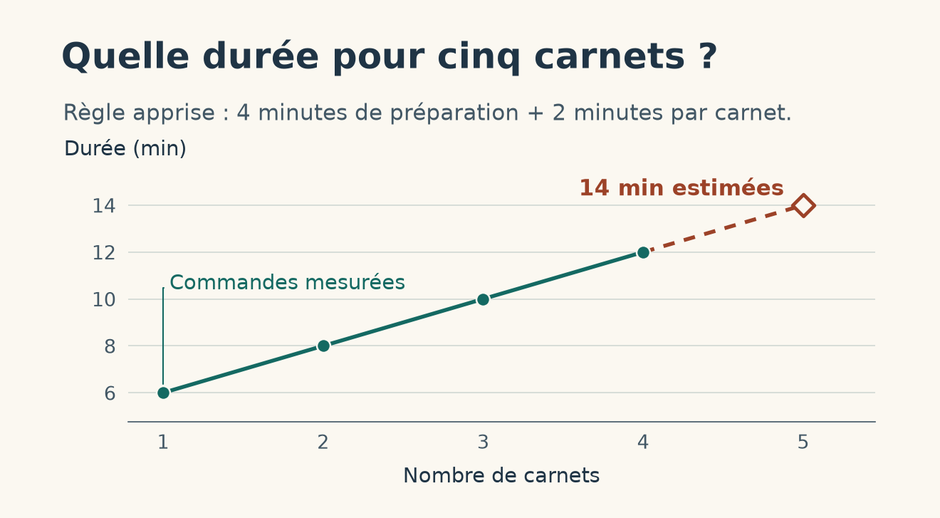

Les ronds sont des mesures. Le losange est une estimation. Si la commande de cinq carnets dure finalement 17 minutes, le client aura attendu **3 minutes de plus** que prévu. L’écart « durée mesurée moins durée prédite » s’appelle un **résidu**.

> **Essaie une autre durée.** Dans `essais`, remplace la dernière durée de 12 par 16. Rejoue la cellule d’entraînement puis celle des prédictions. Qu’obtiens-tu pour cinq carnets ? Rétablis 12 et rejoue ces deux cellules pour revenir au dessin.

<details><summary>Lire le résultat</summary>

L’estimation passe à **18 minutes** pour cinq carnets. La nouvelle droite tient compte d’une quatrième commande plus lente. Si tu modifies seulement la quantité dans `a_preparer`, la règle apprise reste la même. Pour cent carnets, Python donnerait aussi un nombre, alors qu’aucun ticket ne montre une commande de cette taille.

</details>

Une seule commande plus lente a suffi à déplacer la droite. Que devient cette règle quand l’imprimeur a plusieurs tickets pour la **même quantité**, avec des durées différentes ?

## Coder · Reprendre l’enquête sur 24 commandes

L’imprimeur ouvre un registre plus fourni. Il s’agit de **24 commandes fictives**, indépendantes des quatre essais de démonstration. Le nombre de carnets est disponible au comptoir. La durée est relevée une fois le travail terminé. Deux commandes de même taille peuvent prendre des durées différentes.

Construis le registre puis repère les deux commandes de trois carnets. Ont-elles pris le même temps ? `registre.index` donne à chaque ligne un numéro de bon, de C01 à C24, pour que tu puisses retrouver la commande sur le dessin.

In [8]:
registre = pd.DataFrame({
    "carnets": [3, 8, 2, 11, 6, 4, 9, 1, 12, 5, 8, 3,
                10, 4, 7, 6, 2, 9, 11, 5, 7, 12, 1, 10],
    "minutes": [10, 22, 9, 24, 17, 13, 23, 7, 28, 13, 18, 12,
                25, 11, 21, 16, 7, 22, 27, 18, 16, 31, 6, 23],
})
registre.index = [f"C{numero:02}" for numero in range(1, len(registre) + 1)]
registre.index.name = "commande"
registre

,carnets,minutes
commande,,
C01,3,10
C02,8,22
C03,2,9
C04,11,24
C05,6,17
C06,4,13
C07,9,23
C08,1,7
C09,12,28


Les commandes **C01** et **C12** contiennent chacune trois carnets. L’une a pris 10 minutes et l’autre 12. Le numéro de commande sert à retrouver une ligne. Il reste hors de X.

Pour découvrir si la quantité aide malgré cette différence, reprends l’idée de l’enveloppe. Réserve **un quart** des commandes pour le test. `train_test_split` partage X et y ensemble pour conserver les paires. `random_state=42` fixe le tirage et permet de retrouver les mêmes commandes en rejouant le cahier.

In [19]:
from sklearn.model_selection import train_test_split

X = registre[["carnets"]]
y = registre["minutes"]
X_ap, X_test, y_ap, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print(f"Apprentissage : {len(X_ap)} commandes")
print(f"Test : {len(X_test)} commandes")

Apprentissage : 18 commandes
Test : 6 commandes


Les **18 commandes d’apprentissage** sont sur la table et les **6 autres** sont réservées. Entraîne une nouvelle droite sur les 18. À quoi la comparer pour savoir si la quantité apporte vraiment quelque chose ? Si l’imprimeur ignorait la quantité, il pourrait annoncer à tout le monde la **durée moyenne de l’apprentissage**. Cette annonce identique pour tous servira de **référence**, un point de comparaison facile à reproduire. Les deux règles auront exactement les mêmes six commandes à prévoir.

In [22]:
modele_atelier = LinearRegression()
modele_atelier.fit(X_ap, y_ap)
moyenne_ap = y_ap.mean()

print(f"Durée estimée = {modele_atelier.intercept_:.2f} + {modele_atelier.coef_[0]:.2f} × carnets")
print(f"Référence à annoncer à tous : {moyenne_ap:.2f} min")

Durée estimée = 4.83 + 1.96 × carnets
Référence à annoncer à tous : 17.89 min


Un carnet de plus fait monter l’estimation d’environ **1,96 minute**. Cette augmentation par carnet s’appelle la **pente** de la droite. Le second nombre, **4,83 minutes**, s’appelle l’**ordonnée à l’origine**. C’est la valeur donnée par la droite pour zéro carnet, en dehors des quantités observées. On peut y voir une hypothèse sur la préparation, sans pouvoir la vérifier avec ce registre.

À présent, prédis les durées avec `X_test`. Ensuite seulement, ouvre les réponses `y_test`. Un résidu positif correspond à une attente plus longue qu’annoncé. Un résidu négatif correspond à une commande finie plus tôt. Repère la ligne C17 dans le résultat. Où verras-tu cet écart sur le dessin ?

In [23]:
predictions_test = modele_atelier.predict(X_test)
bilan = X_test.copy()
bilan["mesure_min"] = y_test
bilan["prediction_min"] = predictions_test
bilan["residu_min"] = bilan["mesure_min"] - bilan["prediction_min"]
bilan.round(2)

,carnets,mesure_min,prediction_min,residu_min
commande,,,,
C09,12,28,28.34,-0.34
C17,2,7,8.75,-1.75
C01,3,10,10.71,-0.71
C19,11,27,26.38,0.62
C12,3,12,10.71,1.29
C10,5,13,14.62,-1.62


### Visualiser · Où se situe l’erreur de C17 ?

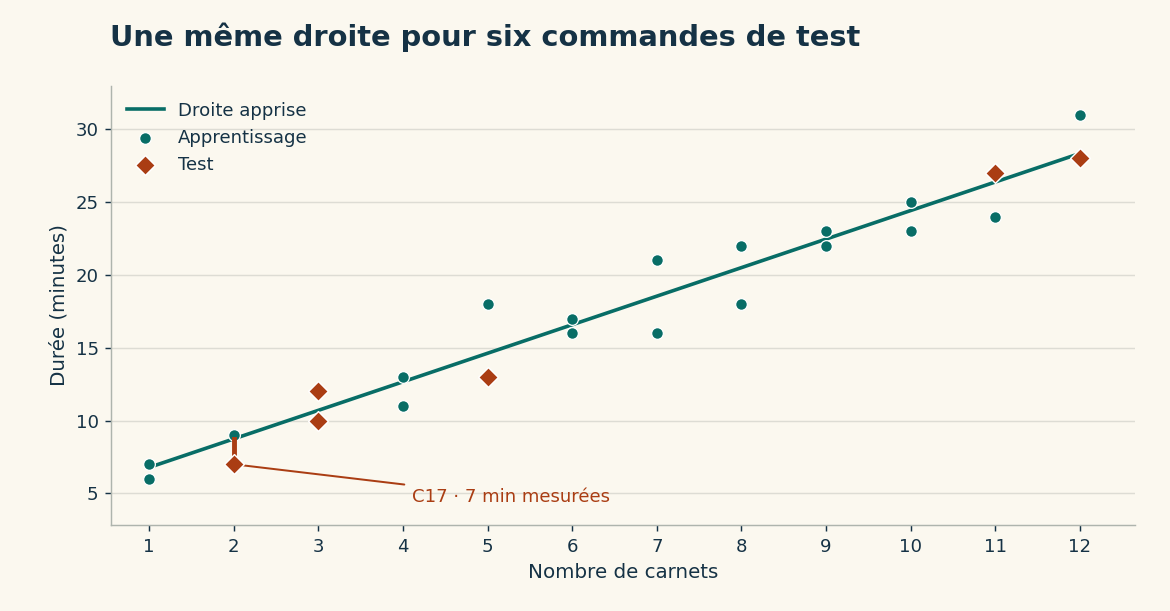

Pour C17, la droite annonce **8,75 minutes** et la machine en a mis **7**. Le segment vertical mesure l’écart entre les deux. Compare avec les deux losanges alignés à trois carnets. La droite donne une seule estimation pour ces deux commandes, mais chacune a son propre résidu.

L’une des deux commandes de trois carnets a pris moins de temps qu’annoncé, l’autre en a pris davantage. Comment donner à la cliente une idée de l’erreur habituelle sans que l’avance de l’une efface le retard de l’autre ?

## De combien de minutes se trompe-t-on en général ?

Suppose qu’une commande finisse **2 minutes en avance** et une autre **2 minutes en retard**. Si on additionne −2 et +2, on obtient zéro. Pourtant, chaque annonce s’est trompée de deux minutes.

Pour mesurer la **taille** de l’erreur, on compte 2 dans les deux cas. Enlever le signe d’un écart, c’est prendre sa *valeur absolue*. On fait ensuite la moyenne. Ce calcul s’appelle l’**erreur absolue moyenne**, abrégée **MAE** en anglais.

Pour C17, on compte donc **1,75 minute**. Fais de même sur les six commandes avec `.abs()`, puis `.mean()` pour prendre la moyenne.

In [12]:
residus = bilan["residu_min"]
mae = residus.abs().mean()
print(f"Écart moyen entre l’annonce et la durée mesurée : {mae:.2f} min")

Écart moyen entre l’annonce et la durée mesurée : 1.05 min


La droite se trompe en moyenne d’environ **1,05 minute** sur ces six tickets. Pour l’imprimeur, un très gros retard peut toutefois désorganiser le reste de l’après-midi. Comment faire peser davantage les grands écarts dans le calcul ?

### Donner plus de poids aux grosses erreurs

Multiplie chaque écart par lui-même. Un écart de 2 minutes donne 4, un écart de 4 minutes donne 16. Doubler l’écart lui donne donc **quatre fois plus de poids**. La moyenne de ces carrés s’appelle l’**erreur quadratique moyenne** ou **MSE**. Elle s’exprime en minutes **au carré**.

Pour retrouver une grandeur en minutes, on prend la *racine carrée* du résultat. C’est le nombre qui, multiplié par lui-même, redonne cette moyenne. On obtient ainsi la **RMSE**, la racine de l’erreur quadratique moyenne. Dans le code, `** 2` calcule le carré et `** 0.5` la racine carrée.

In [13]:
mse = (residus ** 2).mean()
rmse = mse ** 0.5
print(f"Moyenne des carrés des erreurs : {mse:.2f} min²")
print(f"Après la racine carrée : {rmse:.2f} min")

Moyenne des carrés des erreurs : 1.39 min²
Après la racine carrée : 1.18 min


La MSE vaut **1,39 min²**. Pour parler à la cliente, utilise plutôt la MAE (**1,05 min**) ou la RMSE (**1,18 min**), deux mesures qui se lisent en minutes. Une autre question intéresse l’imprimeur. Sa droite suit-elle bien les différences de durée entre petites et grosses commandes ?

### La droite suit-elle les variations de durée ?

Pour le vérifier, imagine qu’on donne à chaque commande la durée moyenne **des six tickets du test**. Calcule la somme des erreurs au carré de cette annonce unique. Elle indique combien les durées de ces six tickets varient autour de leur moyenne. Compare-la à la somme des erreurs au carré de la droite.

Le **coefficient de détermination**, noté **R²**, traduit cette comparaison par un nombre sans unité. Une droite parfaite donne 1. Si elle fait aussi bien que la moyenne de ces tickets, le score vaut 0. Si elle fait moins bien, il devient négatif. Un score de 0,9 ne signifie donc pas que neuf commandes sur dix ont été prédites exactement.

In [14]:
dispersion_test = ((y_test - y_test.mean()) ** 2).sum()
erreur_droite = (residus ** 2).sum()
r2 = 1 - erreur_droite / dispersion_test
print(f"Part des variations suivie par la droite (R²) : {r2:.3f}")

Part des variations suivie par la droite (R²) : 0.979


Le calcul donne **0,979**. Sur ces six commandes, il reste environ **2,1 %** de la somme des écarts au carré obtenue avec la moyenne du test. Cette moyenne sert à **lire le score** après coup. Au comptoir, l’imprimeur connaissait seulement la moyenne de ses 18 anciens tickets, **17,89 minutes**. Qu’aurait donné cette annonce fixe face à la droite ?

La fonction `mesurer` ci-dessous répète les calculs pour chaque règle avec les outils de scikit-learn. Elle reçoit les vraies durées et les annonces correspondantes. `[moyenne_ap] * len(y_test)` prépare six fois la même annonce. Dans le tableau final, chaque ligne correspond à une règle et chaque colonne à une mesure que tu viens de calculer.

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def mesurer(durees, estimations):
    erreur_carree = mean_squared_error(durees, estimations)
    return {
        "MAE (min)": mean_absolute_error(durees, estimations),
        "MSE (min²)": erreur_carree,
        "RMSE (min)": erreur_carree ** 0.5,
        "R²": r2_score(durees, estimations),
    }

reference_test = [moyenne_ap] * len(y_test)
comparaison = pd.DataFrame({
    "Droite": mesurer(y_test, predictions_test),
    "Moyenne d’apprentissage": mesurer(y_test, reference_test),
}).T
comparaison.round(3)

,MAE (min),MSE (min²),RMSE (min),R²
Droite,1.055,1.393,1.180,0.979
Moyenne d’apprentissage,8.130,70.772,8.413,-0.044


**Que dire au comptoir ?** Sur les six commandes réservées, la droite se trompe en moyenne de **1,05 minute**, contre **8,13 minutes** pour l’annonce fixe. La quantité de carnets aide donc à estimer la durée sur ce petit lot. Le R² légèrement négatif de l’annonce fixe (−0,044) vient de la différence entre les moyennes de l’apprentissage et du test.

Une erreur *moyenne* d’environ une minute ne garantit rien pour un client pris individuellement. L’imprimeur a justement conservé les trois bons du samedi. Sur lequel a-t-il fait attendre son client beaucoup plus longtemps que prévu ?

## Pratiquer · L’annonce du samedi a-t-elle tenu ?

Samedi, trois clients reviennent chercher leurs carnets. L’imprimeur a utilisé la **droite du registre** pour leur annoncer un délai. Une estimation trop courte de **plus de cinq minutes** mérite qu’il relise le bon de fabrication.

| Bon du samedi | Carnets | Durée mesurée |
|---|---:|---:|
| S1 | 3 | 12 min |
| S2 | 6 | 18 min |
| S3 | 9 | 30 min |

1. Dans la cellule ci-dessous, ajoute une colonne de prédictions en utilisant le modèle déjà entraîné. Quelles colonnes peux-tu lui montrer au comptoir ?
2. Calcule le résidu de chaque bon. Lequel l’imprimeur doit-il relire ?
3. Calcule la MAE des trois annonces et celle de la référence apprise sur le registre. Rédige deux phrases pour l’imprimeur. Indique quelle règle tu garderais et ce que tu irais vérifier à l’atelier.

<details><summary>Un indice si tu bloques</summary>

La sélection `samedi[["carnets"]]` a la même forme que X. Pour le signalement, pars de « mesure moins prédiction » et cherche un écart supérieur à 5. Tu peux réutiliser `mean_absolute_error` et `moyenne_ap`.

</details>

In [16]:
samedi = pd.DataFrame(
    {"carnets": [3, 6, 9], "minutes": [12, 18, 30]},
    index=["S1", "S2", "S3"],
)
# Ajoute ici tes prédictions, tes résidus et les deux MAE.
samedi

,carnets,minutes
S1,3,12
S2,6,18
S3,9,30


### Corrigé du samedi

Exécute cette proposition après avoir essayé. La colonne de durées reste cachée pendant `predict`. Elle redevient utile pour calculer les résidus et les MAE.

In [ ]:
from sklearn.metrics import mean_absolute_error

# Copier le tableau pour ajouter des colonnes sans modifier le tableau samedi.
controle_samedi = samedi.copy()

controle_samedi["prediction_min"] = modele_atelier.predict(samedi[["carnets"]])
controle_samedi["residu_min"] = samedi["minutes"] - controle_samedi["prediction_min"]

# Afficher le tableau avec deux décimales.
display(controle_samedi.round(2))

# Récupérer les noms des séances qui ont duré plus de 5 minutes de plus que prévu.
a_relire = controle_samedi.index[controle_samedi["residu_min"] > 5]

# Afficher les noms séparés par des virgules, ou "aucune ligne" si la liste est vide.
print("Bon à relire :", ", ".join(a_relire) if len(a_relire) else "aucune ligne")

# Comparer les durées réelles aux prédictions de la droite.
mae_droite = mean_absolute_error(samedi["minutes"], controle_samedi["prediction_min"])

# La référence prédit toujours la même durée : la moyenne d'apprentissage.
mae_reference = mean_absolute_error(samedi["minutes"], [moyenne_ap] * len(samedi))

# Afficher les 2 MAE en minutes. La + petite indique la méthode qui se trompe le - en avg sur les séances du samedi.
print(f"MAE de la droite : {mae_droite:.2f} min")

,carnets,minutes,prediction_min,residu_min
S1,3,12,10.71,1.29
S2,6,18,16.58,1.42
S3,9,30,22.46,7.54


'Bon à relire :'

'S3'

'MAE de la droite : 3.42 min'

'MAE de la référence : 6.04 min'

Les annonces étaient de **10,71**, **16,58** et **22,46 minutes**. Les clients ont attendu respectivement **1,29**, **1,42** et **7,54 minutes** de plus. Le bon **S3** dépasse le seuil prévu.

Exemple de restitution à l’imprimeur. « Sur ces trois commandes, je garderais la droite, avec une erreur moyenne de **3,42 min** contre **6,04 min** pour le délai fixe. Pour S3, je relirais le bon de fabrication avec la personne qui a préparé la commande avant de proposer une explication. »

Avant de conseiller définitivement cette règle, quelles précautions prises sur le registre voudrais-tu aussi garder pour la prochaine série de commandes ?

## Retenir · Les questions à se poser au comptoir

| Erreur classique | Question à se poser |
|---|---|
| Confondre deux questions | Est-ce que je cherche une durée en minutes ou simplement la réponse « à l’heure » ou « en retard » ? |
| Glisser la vraie durée dans X | L’imprimeur connaît-il cette information au moment de l’annonce ? |
| Apprendre et se noter sur les mêmes commandes | Quelles lignes sont restées hors de `fit` jusqu’à l’évaluation ? |
| Présenter la MSE comme un délai | S’agit-il de minutes, de minutes au carré ou d’un score sans unité ? |
| Présenter un bon score comme une promesse individuelle | Quelle est l’erreur moyenne, face à quelle référence, sur combien de commandes ? |

Sur le bon du samedi, l’imprimeur a pu mesurer **combien de minutes** le client a attendu en plus. Dans un autre carnet, il a seulement coché « à l’heure » ou « en retard ». Pour la prochaine commande, la cliente voudrait savoir **laquelle de ces deux réponses** lui annoncer. Apprendre à choisir entre des réponses déjà définies s’appelle la **classification**. Comment l’imprimeur peut-il faire ce choix avec ses anciens tickets ?